# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Lioneil Diyoel Trystan Tikupadang | 5054251037 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

dataset = "data/breast_cancer.csv"
df = pd.read_csv(dataset)

df.columns = df.columns.str.strip()

print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

print("\nTipe data:")
print(df.dtypes.value_counts())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nMissing value per kolom (hanya yang > 0):")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nTotal missing value:", df.isna().sum().sum())

Jumlah baris : 569
Jumlah kolom : 33

Tipe data:
float64    31
int64       1
str         1
Name: count, dtype: int64

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_s

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01



Missing value per kolom (hanya yang > 0):
Unnamed: 32    569
dtype: int64

Total missing value: 569


diagnosis
B    357
M    212
Name: count, dtype: int64

Proporsi (%):
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


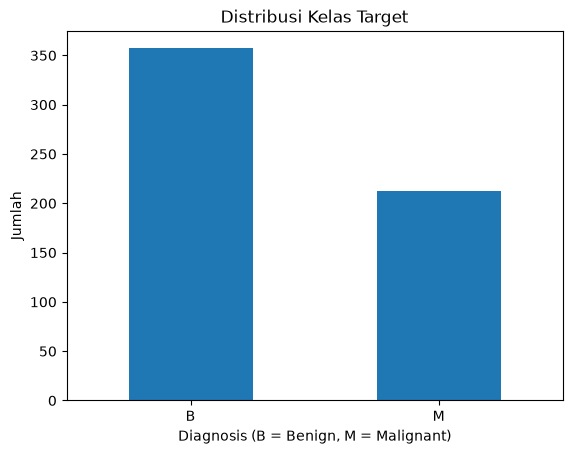

In [4]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

print(df['diagnosis'].value_counts())
print("\nProporsi (%):")
print((df['diagnosis'].value_counts(normalize=True) * 100).round(2))

df['diagnosis'].value_counts().plot(kind='bar')
plt.xlabel('Diagnosis (B = Benign, M = Malignant)')
plt.ylabel('Jumlah')
plt.title('Distribusi Kelas Target')
plt.xticks(rotation=0)
plt.show()

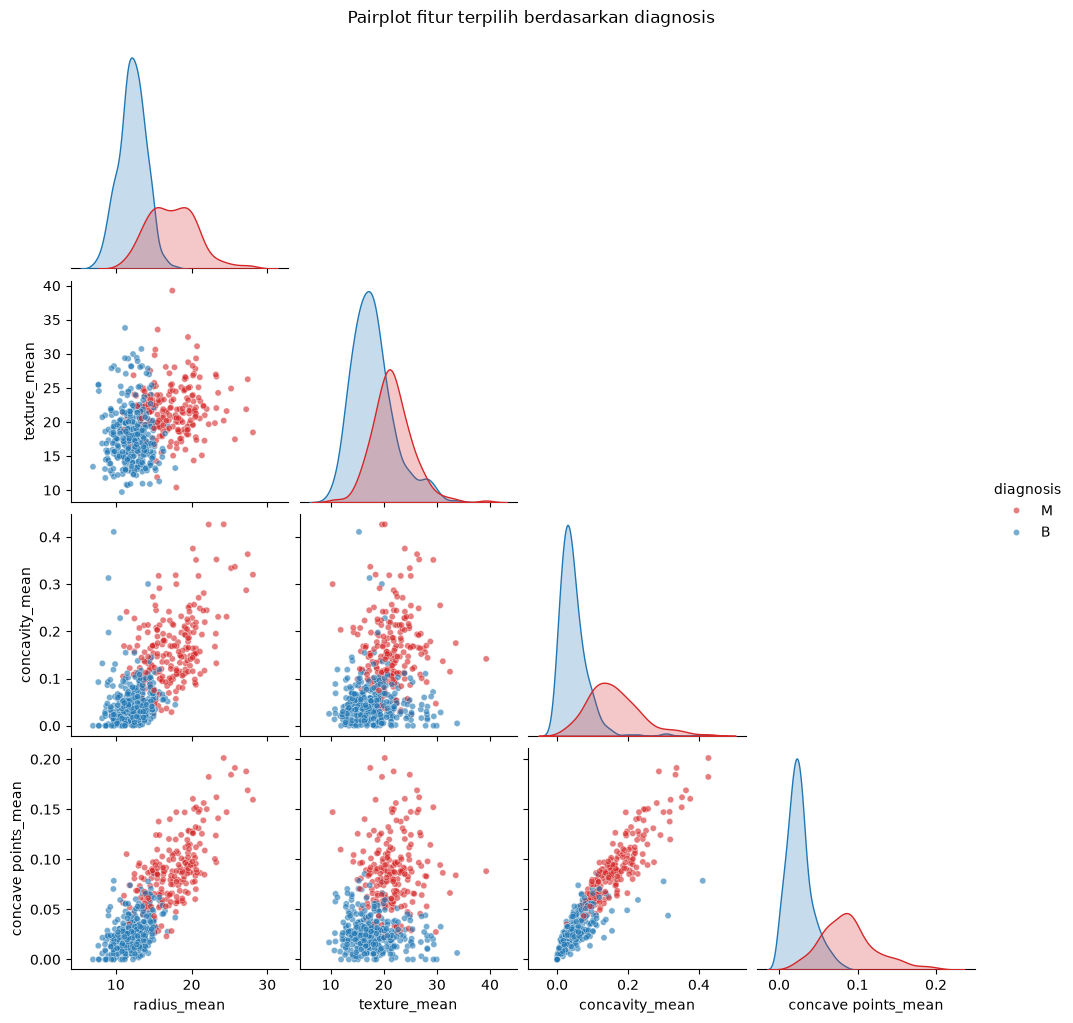

In [7]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.

pair_cols = ['radius_mean', 'texture_mean', 'concavity_mean', 'concave points_mean']
sns.pairplot(df[pair_cols + ['diagnosis']], hue='diagnosis', corner=True, palette={'B': 'tab:blue', 'M': 'tab:red'}, plot_kws={'alpha': 0.6, 's': 20})
plt.suptitle('Pairplot fitur terpilih berdasarkan diagnosis', y=1.02)
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

10 fitur dengan korelasi tertinggi terhadap diagnosis (1 = Malignant):
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660


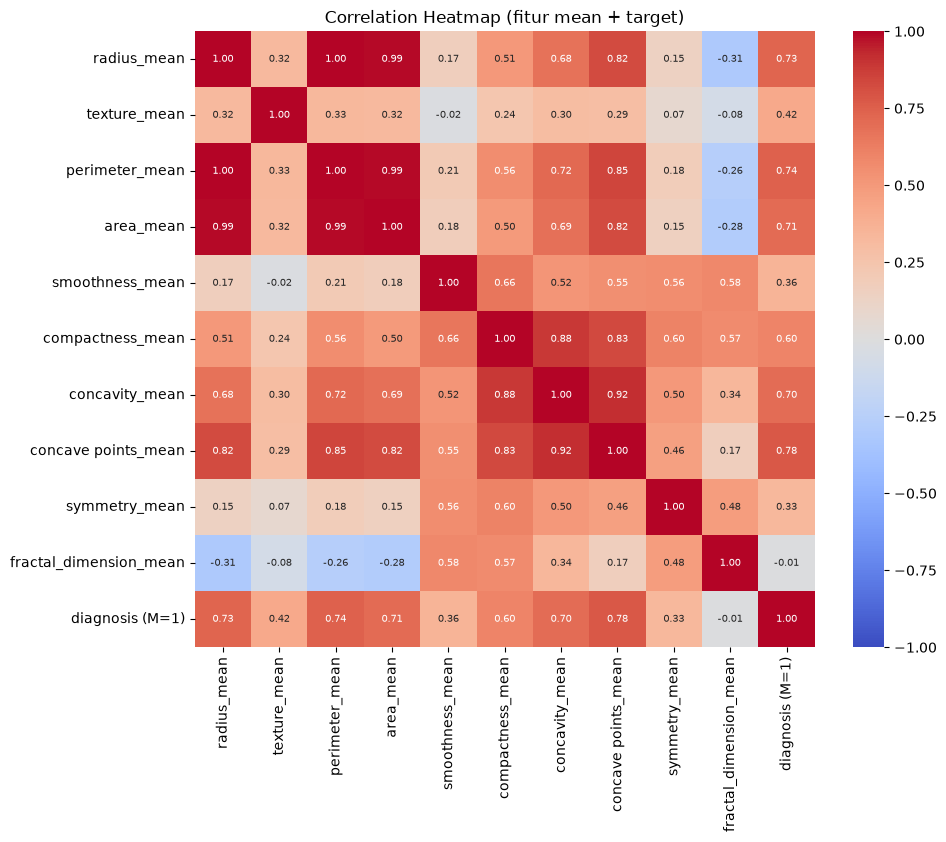


Jumlah pasangan fitur dengan |korelasi| > 0.95: 15
radius_mean      perimeter_mean     0.998
radius_worst     perimeter_worst    0.994
radius_mean      area_mean          0.987
perimeter_mean   area_mean          0.987
radius_worst     area_worst         0.984
perimeter_worst  area_worst         0.978

Rentang nilai terbesar dan terkecil antar fitur:
                           min        max    rentang
fractal_dimension_se    0.0009     0.0298     0.0289
smoothness_se           0.0017     0.0311     0.0294
area_mean             143.5000  2501.0000  2357.5000
area_worst            185.2000  4254.0000  4068.8000


In [10]:
feat_cols = [c for c in df.columns if c not in ['id', 'diagnosis', 'Unnamed: 32']]
target_num = (df['diagnosis'] == 'M').astype(int)

corr_target = df[feat_cols].corrwith(target_num).sort_values(ascending=False)
print("10 fitur dengan korelasi tertinggi terhadap diagnosis (1 = Malignant):")
print(corr_target.head(10).round(3).to_string())

# Correlation heatmap untuk 10 fitur mean + target
plt.figure(figsize=(10, 8))
corr_mat = pd.concat([df[mean_cols], target_num.rename('diagnosis (M=1)')], axis=1).corr()
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Correlation Heatmap (fitur mean + target)')
plt.show()

# Pasangan fitur dengan korelasi sangat tinggi (|r| > 0.95)
c = df[feat_cols].corr().abs()
pairs = (c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().loc[lambda s: s > 0.95].sort_values(ascending=False))
print(f"\nJumlah pasangan fitur dengan |korelasi| > 0.95: {len(pairs)}")
print(pairs.head(6).round(3).to_string())

# Perbedaan skala antar fitur
rng = df[feat_cols].agg(['min', 'max']).T
rng['rentang'] = rng['max'] - rng['min']
print("\nRentang nilai terbesar dan terkecil antar fitur:")
print(rng.sort_values('rentang').iloc[[0, 1, -2, -1]].round(4).to_string())


# 2. Preprocessing

In [11]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

df = df.drop(columns=['Unnamed: 32', 'id'])

print("Ukuran data setelah pembersihan:", df.shape)
print("Total missing value             :", df.isna().sum().sum())
print("Jumlah baris duplikat           :", df.duplicated().sum())

Ukuran data setelah pembersihan: (569, 31)
Total missing value             : 0
Jumlah baris duplikat           : 0


In [12]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).

cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print("Kolom kategorikal:", cat_cols)

df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})
print(df['diagnosis'].value_counts().rename({0: 'B (0)', 1: 'M (1)'}))

Kolom kategorikal: ['diagnosis']
diagnosis
B (0)    357
M (1)    212
Name: count, dtype: int64


In [13]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Ukuran X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nProporsi kelas (train):")
print(y_train.value_counts(normalize=True).round(4))
print("\nProporsi kelas (test):")
print(y_test.value_counts(normalize=True).round(4))


Ukuran X_train: (455, 30) | X_test: (114, 30)

Proporsi kelas (train):
diagnosis
0    0.6264
1    0.3736
Name: proportion, dtype: float64

Proporsi kelas (test):
diagnosis
0    0.6316
1    0.3684
Name: proportion, dtype: float64


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [14]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)  # fit hanya pada train
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)          # test hanya di-transform

print("Mean (train, setelah scaling) - rentang antar fitur:", X_train_scaled.mean().min().round(4), "s/d", X_train_scaled.mean().max().round(4))
print("Std  (train, setelah scaling) - rentang antar fitur:", X_train_scaled.std().min().round(4), "s/d", X_train_scaled.std().max().round(4))

Mean (train, setelah scaling) - rentang antar fitur: -0.0 s/d 0.0
Std  (train, setelah scaling) - rentang antar fitur: 1.0011 s/d 1.0011


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [15]:
# Inisialisasi dan latih model SVC dengan kernel='linear' menggunakan train set (yang sudah discaling).

svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

print("Akurasi train (Linear):", round(svm_linear.score(X_train_scaled, y_train), 4))
print("Jumlah support vectors :", svm_linear.n_support_, "-> total", svm_linear.n_support_.sum())

Akurasi train (Linear): 0.989
Jumlah support vectors : [19 19] -> total 38


In [16]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_linear = svm_linear.predict(X_test_scaled)
print("Akurasi test (Linear):", round(accuracy_score(y_test, y_pred_linear), 4))
print("Contoh 10 prediksi pertama:", y_pred_linear[:10])

Akurasi test (Linear): 0.9649
Contoh 10 prediksi pertama: [0 1 0 0 0 0 1 0 0 0]


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [17]:
# Inisialisasi dan latih model SVC dengan kernel='rbf' menggunakan train set.
# Gunakan nilai hyperparameter lain (C) yang sama seperti model Linear di atas, agar perbandingan adil.

svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

print("Akurasi train (RBF)   :", round(svm_rbf.score(X_train_scaled, y_train), 4))
print("Jumlah support vectors:", svm_rbf.n_support_, "-> total", svm_rbf.n_support_.sum())

Akurasi train (RBF)   : 0.9868
Jumlah support vectors: [50 57] -> total 107


In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_rbf = svm_rbf.predict(X_test_scaled)
print("Akurasi test (RBF):", round(accuracy_score(y_test, y_pred_rbf), 4))
print("Contoh 10 prediksi pertama:", y_pred_rbf[:10])

Akurasi test (RBF): 0.9737
Contoh 10 prediksi pertama: [0 1 0 0 0 0 1 0 0 0]


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [19]:
# Latih beberapa model SVC (kernel RBF) dengan variasi nilai C,
# misalnya 0.01, 0.1, 1, 10, 100.
# Gunakan gamma='scale' atau nilai gamma tetap agar perbandingan fokus pada pengaruh C.

C_values = [0.01, 0.1, 1, 10, 100]
C_models = {}

for C in C_values:
    m = SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
    m.fit(X_train_scaled, y_train)
    C_models[C] = m
    print(f"C = {C:<6} | jumlah support vectors = {m.n_support_.sum()}")

C = 0.01   | jumlah support vectors = 341
C = 0.1    | jumlah support vectors = 202
C = 1      | jumlah support vectors = 107
C = 10     | jumlah support vectors = 82
C = 100    | jumlah support vectors = 70


In [20]:
# Hitung akurasi pada train set dan test set untuk setiap nilai C yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

C_results = []
for C, m in C_models.items():
    C_results.append({
        'C': C,
        'Akurasi Train': accuracy_score(y_train, m.predict(X_train_scaled)),
        'Akurasi Test': accuracy_score(y_test, m.predict(X_test_scaled)),
        'Jumlah SV': int(m.n_support_.sum()),
    })

df_C = pd.DataFrame(C_results)
df_C['Gap (Train - Test)'] = df_C['Akurasi Train'] - df_C['Akurasi Test']
display(df_C.round(4))

,C,Akurasi Train,Akurasi Test,Jumlah SV,Gap (Train - Test)
0,0.01,0.6264,0.6316,341,-0.0052
1,0.10,0.9538,0.9474,202,0.0065
2,1.00,0.9868,0.9737,107,0.0131
3,10.00,0.9890,0.9737,82,0.0153
4,100.00,1.0000,0.9649,70,0.0351


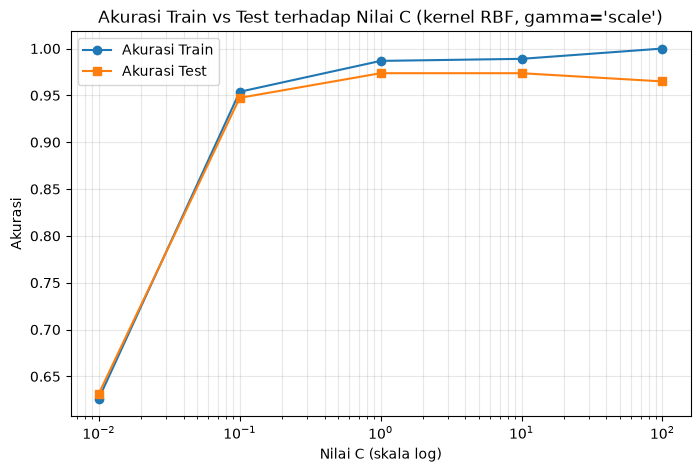

In [21]:
# Plot grafik akurasi training vs testing terhadap nilai C (gunakan sumbu x logaritmik) dalam satu chart.
# Amati pada nilai C berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

plt.figure(figsize=(8, 5))
plt.semilogx(df_C['C'], df_C['Akurasi Train'], marker='o', label='Akurasi Train')
plt.semilogx(df_C['C'], df_C['Akurasi Test'], marker='s', label='Akurasi Test')
plt.xlabel('Nilai C (skala log)')
plt.ylabel('Akurasi')
plt.title("Akurasi Train vs Test terhadap Nilai C (kernel RBF, gamma='scale')")
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.show()

,gamma,Akurasi Train,Akurasi Test,Jumlah SV,Gap (Train - Test)
0,0.0001,0.7846,0.7719,328,0.0127
1,0.0010,0.9495,0.9386,176,0.0109
2,0.0100,0.9758,0.9561,96,0.0197
3,0.1000,0.9890,0.9298,194,0.0592
4,1.0000,1.0000,0.6316,455,0.3684
5,10.0000,1.0000,0.6316,455,0.3684


gamma='scale' pada data ini = 0.0333


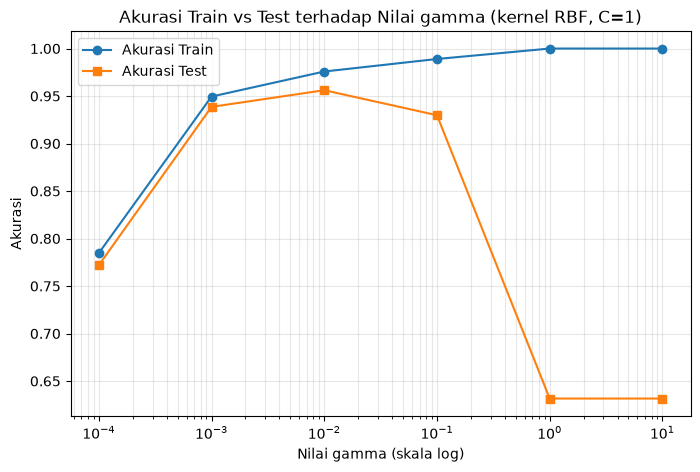

In [22]:
# Eksperimen tambahan: pengaruh gamma terhadap overfitting/underfitting.
gamma_values = [0.0001, 0.001, 0.01, 0.1, 1, 10]
gamma_results = []
for g in gamma_values:
    m = SVC(kernel='rbf', C=1.0, gamma=g, random_state=42).fit(X_train_scaled, y_train)
    gamma_results.append({
        'gamma': g,
        'Akurasi Train': accuracy_score(y_train, m.predict(X_train_scaled)),
        'Akurasi Test': accuracy_score(y_test, m.predict(X_test_scaled)),
        'Jumlah SV': int(m.n_support_.sum()),
    })

df_gamma = pd.DataFrame(gamma_results)
df_gamma['Gap (Train - Test)'] = df_gamma['Akurasi Train'] - df_gamma['Akurasi Test']
display(df_gamma.round(4))
print("gamma='scale' pada data ini =", round(1 / (X_train_scaled.shape[1] * X_train_scaled.values.var()), 4))

plt.figure(figsize=(8, 5))
plt.semilogx(df_gamma['gamma'], df_gamma['Akurasi Train'], marker='o', label='Akurasi Train')
plt.semilogx(df_gamma['gamma'], df_gamma['Akurasi Test'], marker='s', label='Akurasi Test')
plt.xlabel('Nilai gamma (skala log)')
plt.ylabel('Akurasi')
plt.title('Akurasi Train vs Test terhadap Nilai gamma (kernel RBF, C=1)')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.show()


# 4. Evaluasi Model

In [23]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model kernel Linear dan RBF.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

def eval_row(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),   # kelas positif = Malignant (1)
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
    }

eval_table = pd.DataFrame([
    eval_row('SVM Linear (C=1)', y_test, y_pred_linear),
    eval_row("SVM RBF (C=1, gamma='scale')", y_test, y_pred_rbf),
]).set_index('Model')
display(eval_table.round(4))

# Model terbaik: urutkan berdasarkan F1-Score lalu Accuracy
best_name = eval_table.sort_values(['F1-Score', 'Accuracy'], ascending=False).index[0]
best_model = svm_linear if best_name.startswith('SVM Linear') else svm_rbf
print("Model terbaik:", best_name)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
SVM Linear (C=1),0.9649,1.0,0.9048,0.950
"SVM RBF (C=1, gamma='scale')",0.9737,1.0,0.9286,0.963


Model terbaik: SVM RBF (C=1, gamma='scale')


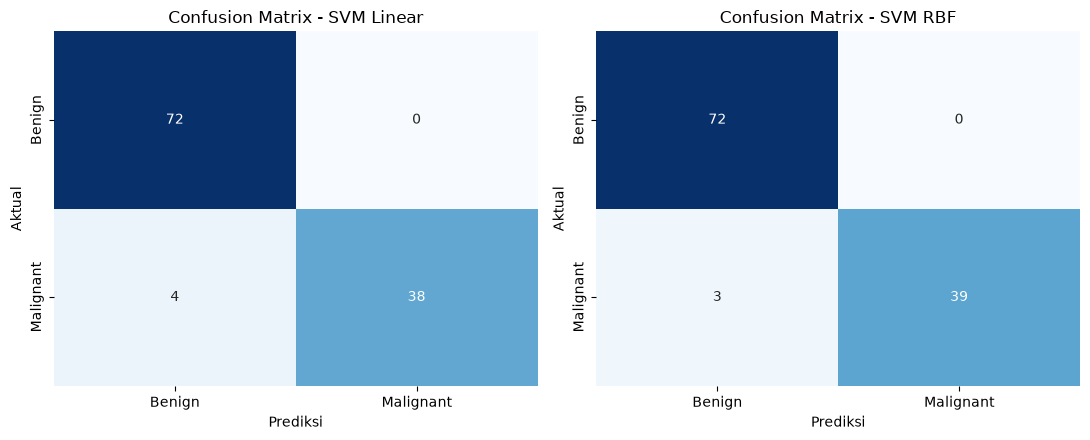

In [25]:
# Tampilkan Confusion Matrix untuk model kernel Linear dan RBF dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [('SVM Linear', y_pred_linear), ('SVM RBF', y_pred_rbf)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    ax.set_title(f'Confusion Matrix - {name}')
plt.tight_layout()
plt.show()

In [26]:
# Tampilkan jumlah support vectors dari model dengan performa terbaik (atribut model.support_vectors_ atau model.n_support_).
# Bandingkan jumlah support vectors antara model Linear dan RBF.

sv_table = pd.DataFrame({
    'Model': ['SVM Linear', 'SVM RBF'],
    'SV Benign': [svm_linear.n_support_[0], svm_rbf.n_support_[0]],
    'SV Malignant': [svm_linear.n_support_[1], svm_rbf.n_support_[1]],
    'Total SV': [svm_linear.support_vectors_.shape[0], svm_rbf.support_vectors_.shape[0]],
}).set_index('Model')
sv_table['% dari Data Train'] = (sv_table['Total SV'] / len(X_train_scaled) * 100).round(1)
display(sv_table)
print("Model terbaik (dari tabel evaluasi):", best_name, "-> total SV =", best_model.support_vectors_.shape[0])

,SV Benign,SV Malignant,Total SV,% dari Data Train
Model,,,,
SVM Linear,19,19,38,8.4
SVM RBF,50,57,107,23.5


Model terbaik (dari tabel evaluasi): SVM RBF (C=1, gamma='scale') -> total SV = 107


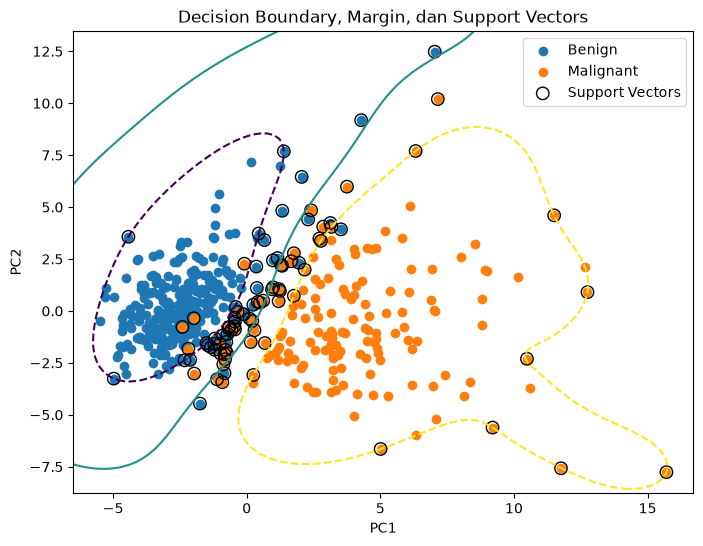

In [29]:
# Jika memungkinkan, pilih dua fitur (atau reduksi dimensi dengan PCA ke 2D) lalu visualisasikan decision boundary
# beserta margin dan support vectors dari model terbaik.

pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_scaled)

svm_2d = SVC(**best_model.get_params())
svm_2d.fit(Z_train, y_train)

x_min, x_max = Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1
y_min, y_max = Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 100),
    np.linspace(y_min, y_max, 100)
)

Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'])

plt.scatter(Z_train[y_train == 0, 0], Z_train[y_train == 0, 1], label='Benign')
plt.scatter(Z_train[y_train == 1, 0], Z_train[y_train == 1, 1], label='Malignant')

# Support vectors
plt.scatter(svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1], facecolors='none', edgecolors='black', s=80, label='Support Vectors')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Decision Boundary, Margin, dan Support Vectors')
plt.legend()
plt.show()


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

#### Hasil Analisis

**Setup eksperimen.** Dataset Breast Cancer Wisconsin memiliki 569 sampel dan 30 fitur numerik (kolom `id` dan `Unnamed: 32` yang 100% kosong dibuang). Kelasnya cukup seimbang: 62,7% Benign dan 37,3% Malignant, jadi tidak ada imbalance yang berat. Data dibagi 80:20 dengan `stratify=y` (train = 455, test = 114) lalu di-scaling dengan `StandardScaler` yang di-fit hanya pada train. Karena test set hanya 114 sampel, **satu sampel salah klasifikasi setara dengan 0,88 poin persen akurasi**; semua perbedaan kecil di bawah ini perlu dibaca dengan konteks tersebut.

**1. Kernel Linear vs RBF (C = 1)**

| Model | Akurasi Train | Akurasi Test | Precision | Recall | F1 | Total SV |
|---|---|---|---|---|---|---|
| Linear | 0,9890 | 0,9649 | 1,0000 | 0,9048 | 0,9500 | 38 |
| RBF (gamma='scale') | 0,9868 | **0,9737** | 1,0000 | 0,9286 | 0,9630 | 107 |

RBF unggul tipis, tetapi selisihnya hanya **1 sampel** (110 vs 111 benar dari 114), sehingga **tidak bisa dikatakan berbeda signifikan**; dengan satu split dan satu seed, urutannya bisa saja terbalik pada split lain. Keduanya memiliki precision 1,0 (tidak ada pasien Benign yang salah diprediksi Malignant), dan perbedaan hanya ada pada recall: Linear melewatkan 4 dari 42 kasus Malignant, RBF melewatkan 3.

Hal ini konsisten dengan hasil EDA. Pada pairplot, titik Benign dan Malignant sudah terpisah cukup jelas pada fitur seperti `radius_mean`, `concavity_mean`, dan `concave points_mean` (korelasi fitur dengan target mencapai 0,79 untuk `concave points_worst`), dengan tumpang tindih hanya di area perbatasan. Ketika kelas sudah hampir terpisah secara linear, hyperplane lurus sudah cukup baik sehingga kemampuan RBF untuk membentuk batas non-linear hanya memberi tambahan kecil. Ini adalah penafsiran dari pola data, bukan sesuatu yang diuji secara terpisah. Dalam konteks medis, recall kelas Malignant lebih penting daripada akurasi, karena kasus ganas yang terlewat (*false negative*) lebih berbahaya daripada alarm palsu.

Alasan scaling diperlukan terlihat dari EDA tambahan: rentang `area_mean` sekitar 2.357, sedangkan `smoothness_se` hanya sekitar 0,029. Tanpa scaling, fitur berskala besar akan mendominasi perhitungan jarak/kernel. Perlu dicatat bahwa notebook ini tidak membandingkan model dengan dan tanpa scaling, jadi pengaruhnya di sini diperkirakan dari perbedaan rentang, bukan diukur langsung.

**2. Eksperimen regularisasi: nilai C (RBF, gamma='scale')**

| C | Akurasi Train | Akurasi Test | Selisih Train-Test | Jumlah SV |
|---|---|---|---|---|
| 0,01 | 0,6264 | 0,6316 | -0,0052 | 341 |
| 0,1 | 0,9538 | 0,9474 | 0,0065 | 202 |
| 1 | 0,9868 | 0,9737 | 0,0131 | 107 |
| 10 | 0,9890 | 0,9737 | 0,0153 | 82 |
| 100 | 1,0000 | 0,9649 | 0,0351 | 70 |

- **Underfitting pada C = 0,01.** Akurasi train (0,6264) dan test (0,6316) sama-sama rendah dan keduanya hampir persis sama dengan proporsi kelas Benign (62,7% / 63,2%), artinya model praktis hanya menebak kelas mayoritas. Regularisasi terlalu kuat sehingga margin sangat lebar dan 341 dari 455 titik train menjadi support vector.
- **Akurasi test terbaik pada C = 1 dan C = 10** (sama-sama 0,9737).
- **Gejala overfitting mulai terlihat pada C = 100.** Akurasi train naik menjadi 1,0000 (menghafal seluruh data train) sementara akurasi test turun menjadi 0,9649, dan selisih train-test melebar dari 0,0131 (C = 1) menjadi 0,0351. Ciri pada grafik: kurva train terus naik hingga menyentuh 1,0 sedangkan kurva test sudah melewati puncaknya dan mulai turun, sehingga jarak antar kedua kurva membesar. Selisih train-test juga naik monoton dari C = 0,1 hingga C = 100. Penurunan test sebesar 1 sampel memang bukti yang lemah jika berdiri sendiri, tetapi arah yang konsisten (selisih terus melebar dan jumlah SV terus menurun) mendukung kesimpulan bahwa C yang besar mulai membuat model terlalu menyesuaikan data train.

**Eksperimen tambahan: gamma (RBF, C = 1).** 

| gamma | Akurasi Train | Akurasi Test | Jumlah SV |
|---|---|---|---|
| 0,0001 | 0,7846 | 0,7719 | 328 |
| 0,001 | 0,9495 | 0,9386 | 176 |
| 0,01 | 0,9758 | 0,9561 | 96 |
| 0,1 | 0,9890 | 0,9298 | 194 |
| 1 | 1,0000 | 0,6316 | 455 |
| 10 | 1,0000 | 0,6316 | 455 |

Gamma yang terlalu kecil (0,0001) menghasilkan underfitting: akurasi train hanya 0,78 karena batas keputusan terlalu halus. Gamma yang besar menghasilkan overfitting yang jauh lebih ekstrem daripada C yang besar: pada gamma = 1 dan 10, akurasi train 1,0000 tetapi akurasi test jatuh ke 0,6316 (sama dengan proporsi kelas Benign di test set), dan **seluruh 455 titik train menjadi support vector**. Artinya pengaruh tiap titik begitu lokal sehingga model menghafal data train dan tidak bisa menggeneralisasi. Nilai `gamma='scale'` pada data ini adalah sekitar 0,033, berada di daerah yang aman di antara 0,01 dan 0,1. Pada grid yang kasar ini, gamma = 0,01 memberi akurasi test tertinggi (0,9561), tetapi masih di bawah model `gamma='scale'` (0,9737), sehingga grid yang lebih halus (atau cross-validation) diperlukan untuk memilih gamma dengan lebih yakin.

**3. Jumlah support vector**

| Model | SV Benign | SV Malignant | Total SV | % dari data train |
|---|---|---|---|---|
| Linear | 19 | 19 | 38 | 8,4% |
| RBF | 50 | 57 | 107 | 23,5% |

Model RBF memerlukan hampir tiga kali lebih banyak support vector daripada Linear. Support vector adalah titik yang berada di margin atau di sisi yang salah, dan merekalah yang menentukan batas keputusan. Batas Linear yang berupa hyperplane lurus hanya perlu ditopang oleh sedikit titik di dekat perbatasan, sedangkan batas RBF yang lebih fleksibel dan melengkung membutuhkan lebih banyak titik untuk "mengatur" bentuknya. Hubungan yang sama muncul di eksperimen C dan gamma: jumlah SV tinggi saat model sangat ter-regularisasi (C = 0,01: 341 SV) maupun saat model sangat kompleks (gamma = 1: 455 SV), dan paling sedikit saat C besar (C = 100: 70 SV) karena margin menyempit dan toleransi terhadap pelanggaran margin berkurang.

Pada visualisasi decision boundary (PCA 2D, model RBF terbaik dilatih ulang pada dua komponen yang menjelaskan 63,1% varians), support vector (lingkaran hitam) menumpuk di sekitar garis batas dan di wilayah tumpang tindih kedua kelas, sedangkan titik yang jauh dari batas bukan support vector. Model 2D ini adalah model terpisah untuk visualisasi dengan akurasi test 0,9298 (lebih rendah dari model 30 fitur karena informasi hilang saat reduksi dimensi), sehingga plotnya hanya ilustrasi bentuk batas keputusan, bukan representasi persis model utama.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

#### Kesimpulan

1. SVM sangat efektif pada dataset Breast Cancer Wisconsin: akurasi test 0,9649 (Linear) dan 0,9737 (RBF), dengan precision 1,0 pada keduanya. Model terbaik adalah SVM RBF (C = 1, gamma='scale') dengan Accuracy 0,9737, Recall 0,9286, dan F1-Score 0,9630.
2. Perbedaan Linear dan RBF hanya 1 sampel pada test set, sehingga belum dapat dianggap signifikan. Hal ini sejalan dengan EDA yang menunjukkan kedua kelas sudah cukup terpisah, sehingga batas linear pun sudah memadai.
3. Parameter C mengendalikan trade-off underfitting dan overfitting: C = 0,01 menyebabkan underfitting (model hanya menebak kelas mayoritas), akurasi test terbaik pada C = 1 hingga 10, dan gejala overfitting mulai terlihat pada C = 100 (train 1,0000, test 0,9649, selisih 0,0351). Gamma lebih sensitif lagi: gamma = 1 atau lebih besar menyebabkan overfitting ekstrem (train 1,0000, test 0,6316).
4. Model Linear lebih sederhana (38 support vector, 8,4% data train) dibanding RBF (107 support vector, 23,5%), mencerminkan batas keputusan RBF yang lebih kompleks.
5. Kelemahan utama yang tersisa adalah kasus Malignant yang terlewat (3 - 4 dari 42), yang berisiko tinggi dalam konteks medis.

#### Saran

- **Evaluasi yang lebih andal:** gunakan stratified k-fold cross-validation (atau ulangi dengan beberapa `random_state`) karena test set hanya 114 sampel, dan pilih hyperparameter dari validation set, bukan dari test set.
- **Hyperparameter tuning:** gunakan `GridSearchCV` pada `C` dan `gamma` secara bersamaan dengan grid yang lebih halus, karena kombinasi keduanya menentukan kompleksitas batas keputusan.
- **Menurunkan false negative:** coba `class_weight='balanced'` atau geser threshold pada `decision_function` agar recall kelas Malignant naik, dengan mempertimbangkan trade-off precision.
- **Kernel dan model lain:** coba kernel Polynomial, serta bandingkan dengan Logistic Regression, Random Forest, atau Gradient Boosting sebagai pembanding.
- **Multikolinearitas:** EDA menunjukkan 15 pasangan fitur dengan korelasi di atas 0,95 (misalnya `radius_mean` dan `perimeter_mean`). Coba seleksi fitur atau PCA dan lihat apakah performa tetap setara dengan fitur yang lebih sedikit.
- **Pengaruh scaling:** bandingkan secara langsung model dengan dan tanpa `StandardScaler` untuk membuktikan efek scaling secara empiris.
